# IMPORT

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import csv
from collections import Counter

# DEFINE FOLDERS

In [3]:
DATASET_INPUT_FOLDER = Path("../data/clean_data_csv")
PLOT_FOLDER = Path("../data/plots")
MISSING_STATION_DATA_FOLDER = Path("../data/missing_station_data")
STATISTICS_DATA_FOLDER = Path("../data/statistics")

folders = [DATASET_INPUT_FOLDER, PLOT_FOLDER, MISSING_STATION_DATA_FOLDER, STATISTICS_DATA_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# LOAD DATA

In [4]:
df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/final_clean_split_data.csv")
df.head(5)

,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,total_bikes_lag1,total_bikes_lag2,split
0,2025-11-04 04:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.000000,8.000000,207.000000,3.000000,0.000000,4,1,0,0.866025,0.500000,2.0,2.0,0
1,2025-11-04 04:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.100000,8.200000,203.000000,3.000000,0.000000,4,1,0,0.866025,0.500000,2.0,2.0,0
2,2025-11-04 05:00:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.094372,9.283279,192.757663,14.660302,0.365327,5,1,0,0.965926,0.258819,2.0,2.0,0
3,2025-11-04 05:15:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.100000,8.100000,201.000000,3.000000,0.000000,5,1,0,0.965926,0.258819,2.0,2.0,0
4,2025-11-04 05:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.100000,8.400000,200.000000,3.000000,0.000000,5,1,0,0.965926,0.258819,2.0,2.0,0


# CONSTANTS

In [5]:
EXPECTED_MINUTES = [0, 15, 30, 45]
EXPECTED_SLOTS_PER_DAY = 24 * 4  # 96

# MISSING DATA COMPUTATION PER STATION

In [6]:
def compute_missing_data(station_id, df):
    df_s = df[df["station_code"] == station_id].copy()

    # Ensure timestamp is datetime
    df_s["timestamp"] = pd.to_datetime(df_s["timestamp"])
    df_s["date"] = df_s["timestamp"].dt.date
    df_s["hour"] = df_s["timestamp"].dt.hour
    df_s["minute"] = df_s["timestamp"].dt.minute

    records = []

    for date, day_df in df_s.groupby("date"):
        # Count how many rows exist for each (hour, minute)
        counts = Counter(zip(day_df["hour"], day_df["minute"]))

        for hour in range(24):
            for minute in EXPECTED_MINUTES:
                records.append({
                    "station_code": station_id,
                    "date": date,
                    "hour": hour,
                    "minute": minute,
                    "present": counts.get((hour, minute), 0)  # number of rows at that time
                })

    return pd.DataFrame(records)

# COMPUTE MISSING DATA FOR ALL STATIONS

In [7]:
all_missing = []

for station_id in df["station_code"].unique():
    all_missing.append(compute_missing_data(station_id, df))

missing_df = pd.concat(all_missing, ignore_index=True)
display(missing_df.head())
missing_df.describe()

,station_code,date,hour,minute,present
0,1001,2025-11-04,0,0,0
1,1001,2025-11-04,0,15,0
2,1001,2025-11-04,0,30,0
3,1001,2025-11-04,0,45,0
4,1001,2025-11-04,1,0,0


,station_code,hour,minute,present
count,6.864000e+06,6.864000e+06,6.864000e+06,6.864000e+06
mean,1.906947e+04,1.150000e+01,2.250000e+01,9.866550e-01
std,1.241148e+04,6.922187e+00,1.677051e+01,1.147471e-01
min,1.001000e+03,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.103600e+04,5.750000e+00,1.125000e+01,1.000000e+00
50%,1.700450e+04,1.150000e+01,2.250000e+01,1.000000e+00
75%,2.240200e+04,1.725000e+01,3.375000e+01,1.000000e+00
max,9.200800e+04,2.300000e+01,4.500000e+01,1.000000e+00


# SAVE IT

In [8]:
missing_df.to_csv(f"{MISSING_STATION_DATA_FOLDER}/missing_data_detailed.csv", index=False)
print(f"Saved: {MISSING_STATION_DATA_FOLDER}/missing_data_detailed.csv")

Saved: ..\data\missing_station_data/missing_data_detailed.csv


# STATION SUMMARY

In [9]:
station_summary = (
    missing_df
    .groupby("station_code")["present"]
    .agg(
        total_slots="count",
        present_slots="sum"
    )
)

station_summary["missing_slots"] = (
    station_summary["total_slots"] - station_summary["present_slots"]
)

station_summary["missing_ratio"] = (
    station_summary["missing_slots"] / station_summary["total_slots"]
)

display(station_summary.sort_values("missing_ratio", ascending=False).head())
display(station_summary.describe())

,total_slots,present_slots,missing_slots,missing_ratio
station_code,,,,
3010,4800,4734,66,0.01375
9001,4800,4734,66,0.01375
2017,4800,4734,66,0.01375
2022,4800,4734,66,0.01375
2110,4800,4734,66,0.01375


,total_slots,present_slots,missing_slots,missing_ratio
count,1430.0,1430.000000,1430.000000,1430.000000
mean,4800.0,4735.944056,64.055944,0.013345
std,0.0,0.329901,0.329901,0.000069
min,4800.0,4734.000000,64.000000,0.013333
25%,4800.0,4736.000000,64.000000,0.013333
50%,4800.0,4736.000000,64.000000,0.013333
75%,4800.0,4736.000000,64.000000,0.013333
max,4800.0,4736.000000,66.000000,0.013750


# SAVE IT

In [10]:
station_summary.to_csv(f"{MISSING_STATION_DATA_FOLDER}/missing_data_by_station.csv")
print(f"Saved: {MISSING_STATION_DATA_FOLDER}/missing_data_by_station.csv")

Saved: ..\data\missing_station_data/missing_data_by_station.csv


# MISSING DATA BY TIMESTAMP

In [11]:
time_summary = (
    missing_df
    .groupby(["hour", "minute"])["present"]
    .mean()
    .reset_index()
)

time_summary["missing_ratio"] = 1 - time_summary["present"]
time_summary.sort_values("missing_ratio", ascending=False).head()

,hour,minute,present,missing_ratio
0,0,0,0.98,0.02
61,15,15,0.98,0.02
70,17,30,0.98,0.02
69,17,15,0.98,0.02
68,17,0,0.98,0.02


# SAVE IT

In [12]:
time_summary.to_csv(f"{MISSING_STATION_DATA_FOLDER}/missing_data_by_timestamp.csv", index=False)
print(f"Saved: {MISSING_STATION_DATA_FOLDER}/missing_data_by_timestamp.csv")

Saved: ..\data\missing_station_data/missing_data_by_timestamp.csv


# MISSING COMPLETE DAYS

In [13]:
daily_summary = (
    missing_df
    .groupby(["station_code", "date"])["present"]
    .sum()
    .reset_index()
)

daily_summary["complete_day_missing"] = (daily_summary["present"] == 0)
daily_summary[daily_summary["complete_day_missing"]].head()

,station_code,date,present,complete_day_missing


# SAVE IT

In [14]:
daily_summary.to_csv(f"{MISSING_STATION_DATA_FOLDER}/missing_data_by_day.csv", index=False)
print(f"Saved: {MISSING_STATION_DATA_FOLDER}/missing_data_by_day.csv")

Saved: ..\data\missing_station_data/missing_data_by_day.csv


# DUPLICATES IN THE DATA

In [15]:
# Check duplicates: same station, same timestamp
duplicates = df[df.duplicated(subset=["station_code", "timestamp"], keep=False)]
print(f"Number of duplicate rows: {duplicates.shape[0]}")

# If you want to see which stations have duplicates
dup_counts = duplicates["station_code"].value_counts().sort_values(ascending=False)
print(dup_counts)


Number of duplicate rows: 0
Series([], Name: count, dtype: int64)


# HISTOGRAM OF ROWS

In [16]:
df_counts = df["station_code"].value_counts().reset_index()
df_counts.columns = ["station_code", "count"]
print(df_counts)

      station_code  count
0             1001   4736
1            20143   4736
2            21017   4736
3            21016   4736
4            21015   4736
...            ...    ...
1433          2004   4734
1434          2003   4734
1435          9101   4734
1436          2001   4734
1437          3010   4734

[1438 rows x 2 columns]


count
4734      40
4736    1398
Name: count, dtype: int64


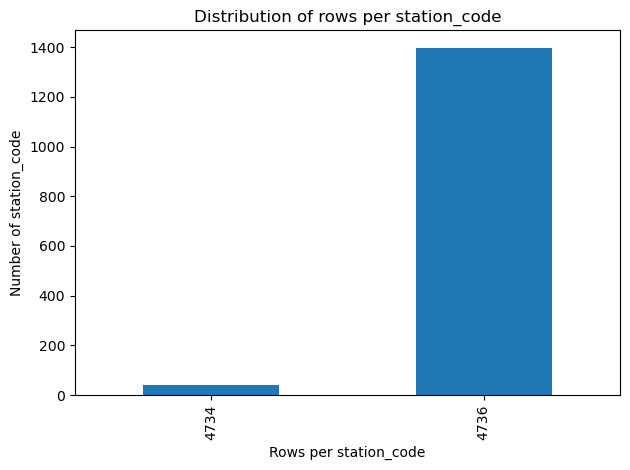

In [17]:
counts = df["station_code"].value_counts()   # index=station_code, value=#rows
count_distribution = counts.value_counts().sort_index()
print(f"{count_distribution}")
count_distribution.plot(kind="bar")
plt.xlabel("Rows per station_code")
plt.ylabel("Number of station_code")
plt.title("Distribution of rows per station_code")
plt.tight_layout()
plt.show()

# STATISTICS FOR EACH STATION

In [18]:
print(f"{df.columns}")
print(df.isna().sum().sort_values(ascending=False))

Index(['timestamp', 'station_code', 'latitude', 'longitude', 'capacity',
       'total_bikes_now', 'total_bikes_taken', 'temperature', 'wind_speed',
       'wind_direction', 'weather_code', 'is_day', 'hour', 'day_of_week',
       'is_weekend', 'sin_hour', 'cos_hour', 'total_bikes_lag1',
       'total_bikes_lag2', 'split'],
      dtype='object')
timestamp            0
station_code         0
total_bikes_lag2     0
total_bikes_lag1     0
cos_hour             0
sin_hour             0
is_weekend           0
day_of_week          0
hour                 0
is_day               0
weather_code         0
wind_direction       0
wind_speed           0
temperature          0
total_bikes_taken    0
total_bikes_now      0
capacity             0
longitude            0
latitude             0
split                0
dtype: int64


In [19]:
excluded_cols = ["station_code", "latitude", "longitude", "timestamp", "wind_direction", "hour", "day_of_week", "is_weekend", "sin_hour", "cos_hour"]
features = [c for c in df.columns if c not in excluded_cols]

station_stats = (
    df.groupby("station_code")[features]
      .agg(["min", "max", "mean", "median"])
)

station_stats.columns = [
    f"{feature}_{stat}" for feature, stat in station_stats.columns
]

station_stats = station_stats.reset_index()

nan_counts = station_stats.isna().sum()

inf_counts = np.isinf(station_stats.select_dtypes(include=[np.number])).sum()

problem_counts = (
    pd.DataFrame({
        "nan": nan_counts,
        "inf": inf_counts
    })
    .fillna(0)
    .astype(int)
    .sort_values(by=["nan", "inf"], ascending=False)
)

print(problem_counts)

                          nan  inf
station_code                0    0
capacity_min                0    0
capacity_max                0    0
capacity_mean               0    0
capacity_median             0    0
total_bikes_now_min         0    0
total_bikes_now_max         0    0
total_bikes_now_mean        0    0
total_bikes_now_median      0    0
total_bikes_taken_min       0    0
total_bikes_taken_max       0    0
total_bikes_taken_mean      0    0
total_bikes_taken_median    0    0
temperature_min             0    0
temperature_max             0    0
temperature_mean            0    0
temperature_median          0    0
wind_speed_min              0    0
wind_speed_max              0    0
wind_speed_mean             0    0
wind_speed_median           0    0
weather_code_min            0    0
weather_code_max            0    0
weather_code_mean           0    0
weather_code_median         0    0
is_day_min                  0    0
is_day_max                  0    0
is_day_mean         

# SAVE IT

In [20]:
station_stats.to_csv(f"{STATISTICS_DATA_FOLDER}/station_statistics.csv", index=False)
print(f"Saved: {STATISTICS_DATA_FOLDER}/station_statistics.csv")

Saved: ..\data\statistics/station_statistics.csv


# PUT THE MISSING DATA IN PLOTS

In [ ]:
def plot_missing_data(station_id, df, save_path=None):
    df_s = df[df["station_code"] == station_id].copy()

    # Snap timestamps to nearest 15min to reduce misalignment issues
    df_s["timestamp"] = pd.to_datetime(df_s["timestamp"]).dt.round("15min")

    # Extract date and time
    df_s["date"] = df_s["timestamp"].dt.date
    df_s["time"] = df_s["timestamp"].dt.time

    # Mark presence
    df_s["present"] = 1

    # Aggregate duplicates
    df_s_agg = df_s.groupby(["date", "time"])["present"].max().reset_index()

    # Pivot
    heatmap_df = df_s_agg.pivot(index="date", columns="time", values="present").fillna(0)

    # Convert time columns to numeric hours for X-axis
    x_labels = [pd.Timestamp.combine(pd.Timestamp.today(), t).hour + pd.Timestamp.combine(pd.Timestamp.today(), t).minute/60 for t in heatmap_df.columns]

    # Plot
    plt.figure(figsize=(18, max(6, len(heatmap_df)/5)))
    plt.imshow(heatmap_df, aspect="auto", cmap="Greens", interpolation="none")
    plt.xticks(ticks=np.linspace(0, len(x_labels)-1, 12), 
               labels=[f"{int(x)}:00" for x in np.linspace(0, 24, 12)], rotation=45)
    plt.yticks(range(len(heatmap_df.index)), [str(d) for d in heatmap_df.index])
    plt.xlabel("Time of day")
    plt.ylabel("Date")
    plt.title(f"Station {station_id} — Missing data pattern")
    plt.colorbar(label="Presence (1=present, 0=missing)")
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)
        plt.close()
    else:
        plt.show()
        plt.close()

# SAVE IT

C:\Users\emirh\AppData\Local\Temp\ipykernel_89460\1717140192.py:25: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.imshow(heatmap_df, aspect="auto", cmap="Greens", interpolation="none")
C:\Users\emirh\AppData\Local\Temp\ipykernel_89460\1717140192.py:25: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.imshow(heatmap_df, aspect="auto", cmap="Greens", interpolation="none")
C:\Users\emirh\AppData\Local\Temp\ipykernel_89460\1717140192.py:25: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.imshow(heatmap_df, aspect="auto", cmap="Greens", interpolation="none")
C:\Users\emirh\AppData\Local\Temp\ipykernel_89460\1717140192.py:25: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.imshow(heatmap_df, aspect="

MemoryError: Unable to allocate 8.95 MiB for an array with shape (883, 1328) and data type int64

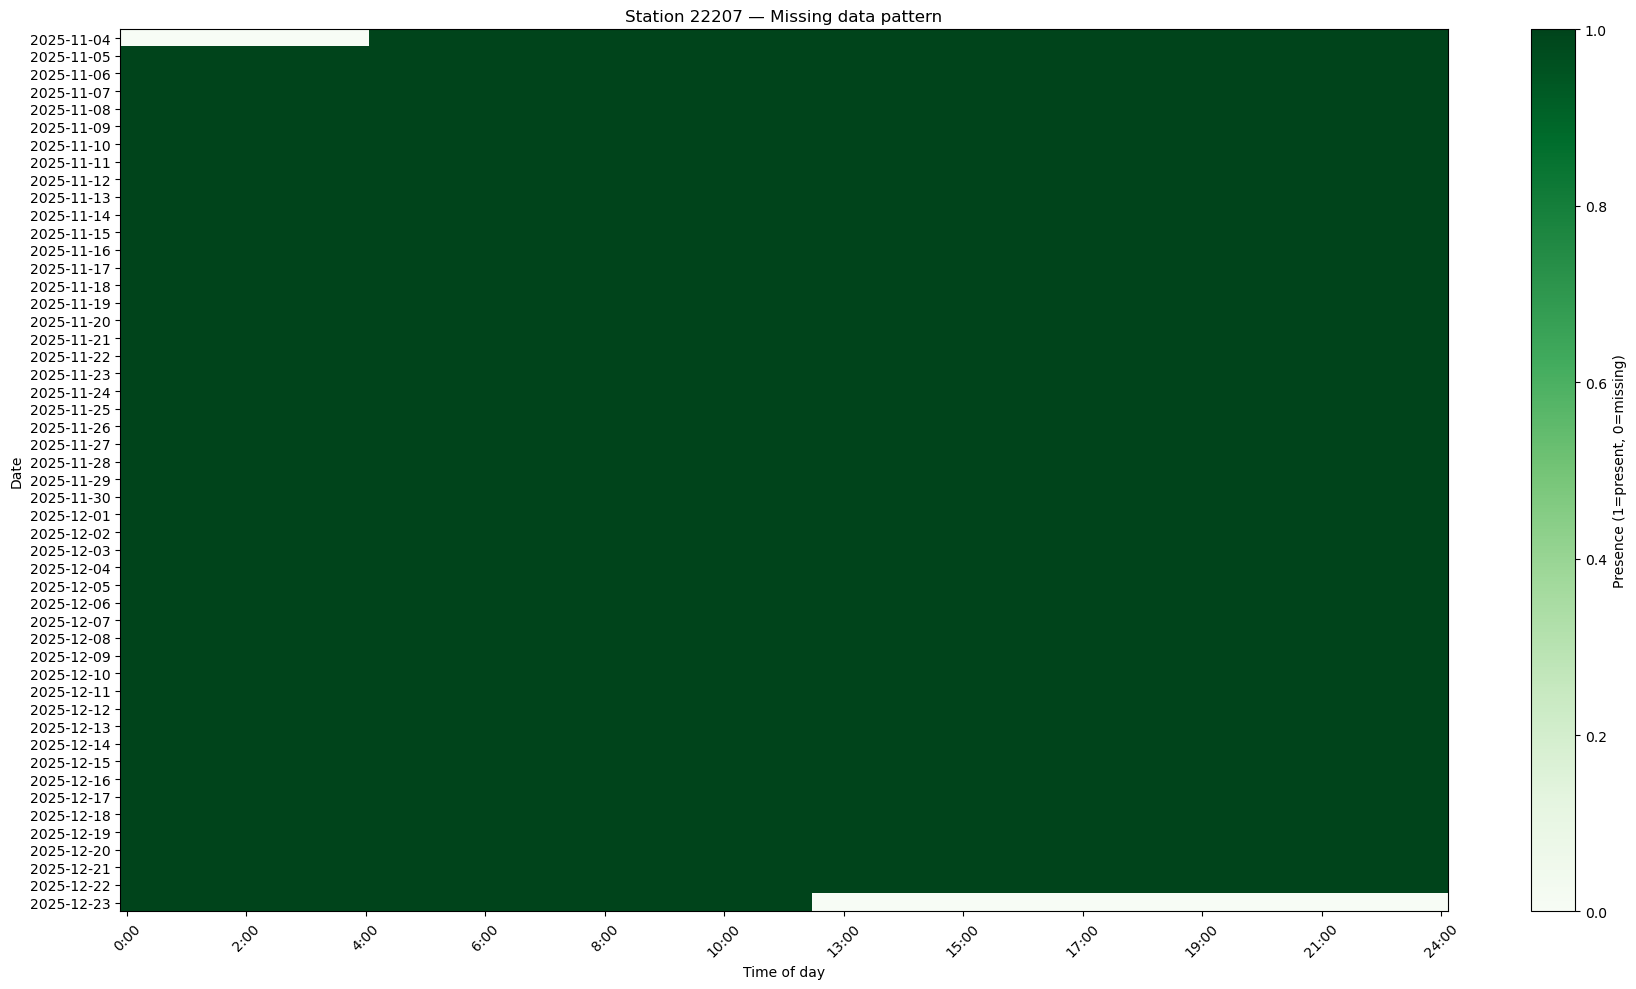

In [22]:
for station_id in df["station_code"].unique():
    plot_missing_data(station_id, df, f"{PLOT_FOLDER}/station_{station_id}.png")

print("All station plots generated.")